# **Finding Williamson-type Hadamard Matrices of order 12 using QAOA**

## **Abstract**
This notebook presents a Quantum Approximate Optimization Algorithm `(QAOA)` approach for constructing Williamson-type Hadamard matrices of Order-12. The problem is formulated as an Ising Hamiltonian optimization task, where the ground state corresponds to a valid Williamson Sequence. The notebook explains the mathematical formulation, Hamiltonian Construction, Quantum circuit generation, expectation value evaluation, and Williamson Matrix reconstruction. In additon, convergence analaysis, quantum circuit visualization, and orthogonality verification are included.

## **Introduction**
Hadamard matrices are square matrices whose entries are $\pm1$ and whose rows are mutually orthogonal. 

A Hadamard matrix `H` satisfies: $$HH^T = nI$$ 

where 
- $H$ is an $n \times n$ Hadamard matrix.
- $H^T$ is the transpose of $H$.
- $I$ is the identity matrix.
- $n$ is the order of the Hadamard matrix.



Williamson construction is a structured method used to generate Hadamard matrices of order $4n$ using four symmetric circulant matrices $A, B, C$ and $D$. The goal of this notebook is to use `QAOA` to search for binary strings that satisfy the Williamson Constraint:
$$AA^T + BB^T + CC^T + DD^T = 4n I$$

For order $12$, we have $n=3$, and the matrices $A, B, C, D$ are of size $3 \times 3$. The binary strings represent the entries of these matrices, and the optimization problem is to find a combination of these strings that satisfies the Williamson constraint.

$$A = \begin{bmatrix} a_0 & a_1 & a_2 \\ a_2 & a_0 & a_1 \\ a_1 & a_2 & a_0 \end{bmatrix}, \quad
B = \begin{bmatrix} b_0 & b_1 & b_2 \\ b_2 & b_0 & b_1 \\ b_1 & b_2 & b_0 \end{bmatrix}, \quad
C = \begin{bmatrix} c_0 & c_1 & c_2 \\ c_2 & c_0 & c_1 \\ c_1 & c_2 & c_0 \end{bmatrix}, \quad
D = \begin{bmatrix} d_0 & d_1 & d_2 \\ d_2 & d_0 & d_1 \\ d_1 & d_2 & d_0 \end{bmatrix}$$

Every variable $a_i, b_i, c_i, d_i$ can take values of either $+1$ or $-1$, therefore, we have eight binary variables to optimize. 
$\boxed{2^8 = 256}$ possible combinations.

For these four matrices to satisfy the Williamson constraint, the following conditions must hold:
1. The sum of the squares of the entries in each row must equal $4n$
2. The sum of the products of corresponding entries in each row must equal $0$ for all pairs of rows.

$$AA^T + BB^T + CC^T + DD^T = 12I_3$$
This is the condition we want our cost function to test. 

We define 
$$C(A, B, C, D) = ||AA^T + BB^T + CC^T + DD^T - 12I_3||^2_F$$

Here the Frobenius norm means that we square every entry of the resulting matrix and add all the squared entries together. The goal is to minimize this cost function, and the minimum value of $C(A, B, C, D)$ is $0$ when the Williamson constraint is satisfied.

For a symmetric circulant matrix of order $3$, the condition can be simplified to the following equations:
$$4 + 2(a_0a1 + b_0b_1 + c_0c_1 + d_0d_1) = 0$$
therefore 
$$\boxed{C_{simple} = [4 + 2 (a_0a_1 + b_0b_1 + c_0c_1 + d_0d_1)]^2}$$

This simpler expressiong is proportional to the Frobenius norm cost.
$$C = 6C_{simple}$$

Both have exactly the same zero-cost solutions. We will initially use the full matrix calculation because it is easier to understand and verify directly.

## **Mathematical Formulation**
The optimization problem is represented using spin variables:
$$s_i \in \{-1, +1\}$$

The Hamiltonian used in this notebook is:
$$
H = 4 + 2s_0s_1 + 2s_2s_3 + 2s_4s_5 + 2s_6s_7
+ s_0s_1s_2s_3 + s_0s_1s_4s_5 + s_0s_1s_6s_7
+ s_2s_3s_4s_5 + s_2s_3s_6s_7 + s_4s_5s_6s_7
$$

The objective is:
$\min H = 0$

If the Hamiltonian energy becomes zero, the corresponding bitstring produces a valid Williamson-type Hadamard matrix.

#### **Install and Import Required Libraries**

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

from scipy.optimize import minimize
from sympy import sympify, symbols

import numpy as np
import matplotlib.pyplot as plt

from collections import Counter
import random

/var/folders/_t/q_d36zn17wv0qrfmtywnt18c0000gn/T/ipykernel_6286/1306540842.py:1: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  from qiskit import QuantumCircuit


# 1. **Finding the 12x12 Hadamard Matrix without QAOA**

In [2]:

import numpy as np
from itertools import product

# =====================================================
# 1. Convert binary values into +1 and -1
# =====================================================

def b2s(x):
    return 1 if x == 0 else -1


# =====================================================
# 2. Construct a symmetric circulant matrix of order 3
# =====================================================

def construct_circulant(bits):

    x0 = b2s(bits[0])
    x1 = b2s(bits[1])

    M = np.array([
        [x0, x1, x1],
        [x1, x0, x1],
        [x1, x1, x0]
    ])

    return M


# =====================================================
# 3. Construct four Williamson matrices
# =====================================================

def construct_williamson_matrices(bitstring):

    A = construct_circulant(bitstring[0:2])
    B = construct_circulant(bitstring[2:4])
    C = construct_circulant(bitstring[4:6])
    D = construct_circulant(bitstring[6:8])

    return A, B, C, D


# =====================================================
# 4. Calculate the Williamson cost function
# =====================================================

def williamson_cost(bitstring):

    A, B, C, D = construct_williamson_matrices(bitstring)

    result = (
        A @ A.T
        + B @ B.T
        + C @ C.T
        + D @ D.T
    )

    target = 12 * np.eye(3, dtype=int)

    difference = result - target

    cost = np.sum(difference ** 2)

    return int(cost)


# =====================================================
# 5. Construct the final 12 x 12 Hadamard matrix
# =====================================================

def construct_hadamard_12(bitstring):

    A, B, C, D = construct_williamson_matrices(bitstring)

    H = np.block([
        [ A,  B,  C,  D],
        [-B,  A, -D,  C],
        [-C,  D,  A, -B],
        [-D, -C,  B,  A]
    ])

    return H


# =====================================================
# 6. Verify the Hadamard condition
# =====================================================

def verify_hadamard(H):

    order = H.shape[0]

    result = H @ H.T

    target = order * np.eye(order, dtype=int)

    return np.array_equal(result, target)


# =====================================================
# 7. Test all 256 possible combinations
# =====================================================

valid_candidates = []
invalid_candidates = []

print("TESTING ALL 256 COMBINATIONS")
print("=" * 50)

for bits in product([0, 1], repeat=8):

    cost = williamson_cost(bits)

    if cost == 0:

        valid_candidates.append(bits)

    else:

        invalid_candidates.append(bits)


# =====================================================
# 8. Display the results
# =====================================================

print("\nFINAL RESULTS")
print("=" * 50)

print("Total candidates:", 256)
print("Valid candidates:", len(valid_candidates))
print("Invalid candidates:", len(invalid_candidates))


# =====================================================
# 9. Display one valid example
# =====================================================

if len(valid_candidates) > 0:

    example = valid_candidates[0]

    print("\nONE VALID BITSTRING:")
    print(example)

    A, B, C, D = construct_williamson_matrices(example)

    print("\nMatrix A:\n", A)
    print("\nMatrix B:\n", B)
    print("\nMatrix C:\n", C)
    print("\nMatrix D:\n", D)

    H = construct_hadamard_12(example)

    print("\nFINAL 12 x 12 HADAMARD MATRIX:")
    print(H)

    print("\nH multiplied by H transpose:")
    print(H @ H.T)

    print("\nIs this a valid Hadamard matrix?")
    print(verify_hadamard(H))


# =====================================================
# 10. Display one invalid example
# =====================================================

if len(invalid_candidates) > 0:

    example_invalid = invalid_candidates[0]

    print("\nONE INVALID BITSTRING:")
    print(example_invalid)

    print("Its Williamson cost is:",
          williamson_cost(example_invalid))

    H_invalid = construct_hadamard_12(example_invalid)

    print("\nDoes it produce a valid Hadamard matrix?")
    print(verify_hadamard(H_invalid))


TESTING ALL 256 COMBINATIONS

FINAL RESULTS
Total candidates: 256
Valid candidates: 64
Invalid candidates: 192

ONE VALID BITSTRING:
(0, 0, 0, 1, 0, 1, 0, 1)

Matrix A:
 [[1 1 1]
 [1 1 1]
 [1 1 1]]

Matrix B:
 [[ 1 -1 -1]
 [-1  1 -1]
 [-1 -1  1]]

Matrix C:
 [[ 1 -1 -1]
 [-1  1 -1]
 [-1 -1  1]]

Matrix D:
 [[ 1 -1 -1]
 [-1  1 -1]
 [-1 -1  1]]

FINAL 12 x 12 HADAMARD MATRIX:
[[ 1  1  1  1 -1 -1  1 -1 -1  1 -1 -1]
 [ 1  1  1 -1  1 -1 -1  1 -1 -1  1 -1]
 [ 1  1  1 -1 -1  1 -1 -1  1 -1 -1  1]
 [-1  1  1  1  1  1 -1  1  1  1 -1 -1]
 [ 1 -1  1  1  1  1  1 -1  1 -1  1 -1]
 [ 1  1 -1  1  1  1  1  1 -1 -1 -1  1]
 [-1  1  1  1 -1 -1  1  1  1 -1  1  1]
 [ 1 -1  1 -1  1 -1  1  1  1  1 -1  1]
 [ 1  1 -1 -1 -1  1  1  1  1  1  1 -1]
 [-1  1  1 -1  1  1  1 -1 -1  1  1  1]
 [ 1 -1  1  1 -1  1 -1  1 -1  1  1  1]
 [ 1  1 -1  1  1 -1 -1 -1  1  1  1  1]]

H multiplied by H transpose:
[[12  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 12  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 12  0  0  0  0  0  0  0  0  0]
 [ 0  0

# 2. **Complete QAOA Implementation**
We have eight binary variables: 
$$x = (a_0, a_1, b_0, b_1, c_0, c_1, d_0, d_1)$$
For convenience, we will denote these four products as:
- $P_1 = a_0a_1$
- $P_2 = b_0b_1$
- $P_3 = c_0c_1$
- $P_4 = d_0d_1$

Then the Simplified cost function can be expressed as:
$$C(x) = [4 + 2(P_1 + P_2 + P_3 + P_4)]^2$$
which gives us the QAOA Objective by explanding the square:
$$C(x) = 32 + 16 \sum_{i=1}^{4} P_i + 8 \sum_{i < j} P_iP_j$$

Our target is: $$\mathrm{min}C(x)= 0$$

### Our QAOA circuit 
 
- Initial state: Eight Hadamard gates creates a uniform superposition of all $2^8 = 256$ possible bitstrings.
- Cost Unitary $U_C(\gamma)$: Encodes the Williamson cost function.
- Mixer $U_B(\beta)$; Applied `RX` rotations to the eight qubits.
- Measurement: Produces candidate bitstrings. 
- Calculate expected cost: Send the results to `COBYLA` or `Nelder-Mead`.


========== COBYLA RESULTS ==========
Optimized gamma: 0.02095250087739484
Optimized beta: -0.14640524620549752
Final expected cost: 9.625
Function evaluations: 21
Optimizer success: True

========== NELDER-MEAD RESULTS ==========
Optimized gamma: 0.0526171875
Optimized beta: 0.04798828125
Final expected cost: 35.046875
Function evaluations: 29
Optimizer success: True


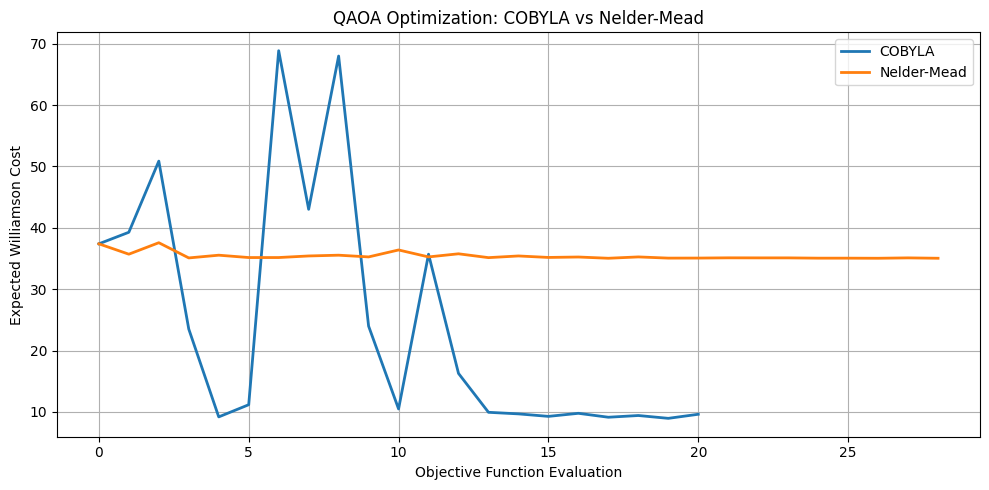


========== BEST MEASURED CANDIDATE ==========
Optimizer: COBYLA
Measured bitstring: 10111001
Variables q0 to q7: (1, 0, 0, 1, 1, 1, 0, 1)
Williamson cost: 0.0

========== HADAMARD VERIFICATION ==========
H =
[[-1  1  1  1 -1 -1 -1 -1 -1  1 -1 -1]
 [ 1 -1  1 -1  1 -1 -1 -1 -1 -1  1 -1]
 [ 1  1 -1 -1 -1  1 -1 -1 -1 -1 -1  1]
 [-1  1  1 -1  1  1 -1  1  1 -1 -1 -1]
 [ 1 -1  1  1 -1  1  1 -1  1 -1 -1 -1]
 [ 1  1 -1  1  1 -1  1  1 -1 -1 -1 -1]
 [ 1  1  1  1 -1 -1 -1  1  1 -1  1  1]
 [ 1  1  1 -1  1 -1  1 -1  1  1 -1  1]
 [ 1  1  1 -1 -1  1  1  1 -1  1  1 -1]
 [-1  1  1  1  1  1  1 -1 -1 -1  1  1]
 [ 1 -1  1  1  1  1 -1  1 -1  1 -1  1]
 [ 1  1 -1  1  1  1 -1 -1  1  1  1 -1]]

H @ H.T =
[[12  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 12  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 12  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 12  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 12  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 12  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 12  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 12  0  0  0  0]

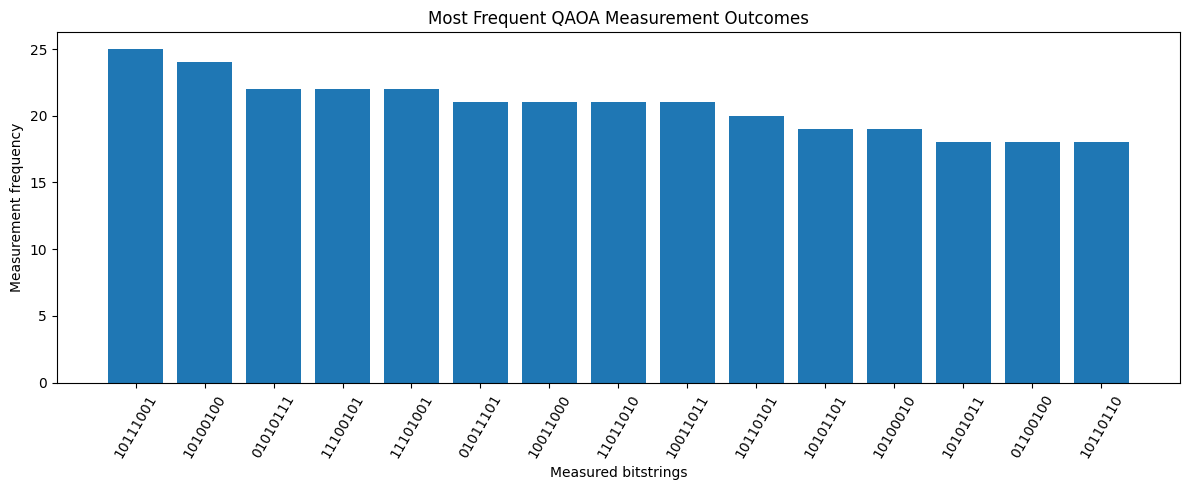

In [3]:
# ============================================================
# QAOA FOR ORDER-12 WILLIAMSON HADAMARD MATRIX
# Eight qubits, QAOA depth p=1
# Classical optimizers: COBYLA and Nelder-Mead
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from itertools import product
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator


# ============================================================
# 1. BINARY TO SIGN CONVERSION
# ============================================================

def b2s(x):
    return 1 if x == 0 else -1


# ============================================================
# 2. CONSTRUCT THE FOUR WILLIAMSON MATRICES
# ============================================================

def construct_circulant(bits):

    x0 = b2s(bits[0])
    x1 = b2s(bits[1])

    return np.array([
        [x0, x1, x1],
        [x1, x0, x1],
        [x1, x1, x0]
    ])


def construct_williamson_matrices(bits):

    A = construct_circulant(bits[0:2])
    B = construct_circulant(bits[2:4])
    C = construct_circulant(bits[4:6])
    D = construct_circulant(bits[6:8])

    return A, B, C, D


# ============================================================
# 3. EXACT WILLIAMSON COST FUNCTION
# ============================================================

def williamson_cost(bits):

    A, B, C, D = construct_williamson_matrices(bits)

    result = A @ A.T + B @ B.T + C @ C.T + D @ D.T

    target = 12 * np.eye(3, dtype=int)

    difference = result - target

    # Full Frobenius cost divided by 6.
    # This has the same minimizers as the full cost.
    cost = np.sum(difference ** 2) / 6

    return float(cost)


# ============================================================
# 4. DEFINE THE COST HAMILTONIAN TERMS
# ============================================================

# Qubits:
# 0,1 = a0,a1
# 2,3 = b0,b1
# 4,5 = c0,c1
# 6,7 = d0,d1

# Two-body terms: coefficient 16
two_body_terms = [
    (16, [0, 1]),
    (16, [2, 3]),
    (16, [4, 5]),
    (16, [6, 7])
]

# Four-body terms: coefficient 8
four_body_terms = [
    (8, [0, 1, 2, 3]),
    (8, [0, 1, 4, 5]),
    (8, [0, 1, 6, 7]),
    (8, [2, 3, 4, 5]),
    (8, [2, 3, 6, 7]),
    (8, [4, 5, 6, 7])
]

cost_terms = two_body_terms + four_body_terms


# ============================================================
# 5. IMPLEMENT THE COST UNITARY
# ============================================================

def apply_cost_term(qc, coefficient, qubits, gamma):

    # Encode the product of Z operators using CNOT gates.
    target = qubits[-1]

    for q in qubits[:-1]:
        qc.cx(q, target)

    # Apply the required phase rotation.
    qc.rz(2 * gamma * coefficient, target)

    # Reverse the CNOT operations.
    for q in reversed(qubits[:-1]):
        qc.cx(q, target)


def apply_cost_unitary(qc, gamma):

    for coefficient, qubits in cost_terms:

        apply_cost_term(
            qc,
            coefficient,
            qubits,
            gamma
        )


# ============================================================
# 6. IMPLEMENT THE MIXER UNITARY
# ============================================================

def apply_mixer_unitary(qc, beta):

    for q in range(8):

        qc.rx(2 * beta, q)


# ============================================================
# 7. CONSTRUCT THE QAOA CIRCUIT
# ============================================================

def create_qaoa_circuit(theta):

    gamma = theta[0]
    beta = theta[1]

    qc = QuantumCircuit(8, 8)

    # Initial uniform superposition
    for q in range(8):
        qc.h(q)

    # Cost unitary
    apply_cost_unitary(qc, gamma)

    # Mixer unitary
    apply_mixer_unitary(qc, beta)

    # Measurement
    qc.measure(range(8), range(8))

    return qc

# ============================================================
# 8. CALCULATE EXPECTED COST FROM MEASUREMENTS
# ============================================================

def compute_expectation(counts):

    total_cost = 0
    total_shots = 0

    for bitstring, count in counts.items():

        # Qiskit displays classical bits in reverse order.
        # Reverse them to recover q0, q1, ..., q7.
        bits = tuple(
            int(x) for x in bitstring.replace(" ", "")[::-1]
        )

        cost = williamson_cost(bits)

        total_cost += cost * count
        total_shots += count

    return total_cost / total_shots


# ============================================================
# 9. SET UP QUANTUM SIMULATOR
# ============================================================

backend = AerSimulator()

SHOTS = 2048

evaluation_history = []


# ============================================================
# 10. DEFINE THE QAOA OBJECTIVE
# ============================================================

def objective(theta):

    qc = create_qaoa_circuit(theta)

    compiled_circuit = transpile(
        qc,
        backend,
        optimization_level=1
    )

    result = backend.run(
        compiled_circuit,
        shots=SHOTS,
        seed_simulator=12345
    ).result()

    counts = result.get_counts()

    expectation_value = compute_expectation(counts)

    evaluation_history.append(expectation_value)

    return expectation_value


# ============================================================
# 11. RUN QAOA WITH COBYLA
# ============================================================

theta0 = [0.05, 0.05]

evaluation_history = []

result_cobyla = minimize(
    fun=objective,
    x0=theta0,
    method="COBYLA",
    options={
        "maxiter": 150,
        "rhobeg": 0.1,
        "tol": 0.001
    }
)

print("\n========== COBYLA RESULTS ==========")

print("Optimized gamma:", result_cobyla.x[0])
print("Optimized beta:", result_cobyla.x[1])
print("Final expected cost:", result_cobyla.fun)
print("Function evaluations:", result_cobyla.nfev)
print("Optimizer success:", result_cobyla.success)


cobyla_history = evaluation_history.copy()


# ============================================================
# 12. RUN QAOA WITH NELDER-MEAD
# ============================================================

evaluation_history = []

result_nm = minimize(
    fun=objective,
    x0=theta0,
    method="Nelder-Mead",
    options={
        "maxiter": 150,
        "xatol": 0.001,
        "fatol": 0.001
    }
)

print("\n========== NELDER-MEAD RESULTS ==========")

print("Optimized gamma:", result_nm.x[0])
print("Optimized beta:", result_nm.x[1])
print("Final expected cost:", result_nm.fun)
print("Function evaluations:", result_nm.nfev)
print("Optimizer success:", result_nm.success)


nm_history = evaluation_history.copy()


# ============================================================
# 13. PLOT OPTIMIZATION CONVERGENCE
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    cobyla_history,
    label="COBYLA",
    linewidth=2
)

plt.plot(
    nm_history,
    label="Nelder-Mead",
    linewidth=2
)

plt.xlabel("Objective Function Evaluation")
plt.ylabel("Expected Williamson Cost")
plt.title("QAOA Optimization: COBYLA vs Nelder-Mead")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 14. SAMPLE THE OPTIMIZED QAOA CIRCUIT
# ============================================================

best_result = (
    result_cobyla
    if result_cobyla.fun <= result_nm.fun
    else result_nm
)

best_optimizer_name = (
    "COBYLA"
    if result_cobyla.fun <= result_nm.fun
    else "Nelder-Mead"
)

final_circuit = create_qaoa_circuit(best_result.x)

final_circuit = transpile(
    final_circuit,
    backend,
    optimization_level=1
)

final_counts = backend.run(
    final_circuit,
    shots=SHOTS,
    seed_simulator=54321
).result().get_counts()


# ============================================================
# 15. DISPLAY THE MOST FREQUENT BITSTRING
# ============================================================

best_bitstring = max(final_counts, key=final_counts.get)

best_bits = tuple(
    int(x) for x in best_bitstring.replace(" ", "")[::-1]
)

print("\n========== BEST MEASURED CANDIDATE ==========")

print("Optimizer:", best_optimizer_name)
print("Measured bitstring:", best_bitstring)
print("Variables q0 to q7:", best_bits)

print("Williamson cost:", williamson_cost(best_bits))


# ============================================================
# 16. CONSTRUCT AND VERIFY THE 12x12 MATRIX
# ============================================================

H = np.block([
    [ construct_williamson_matrices(best_bits)[0],
      construct_williamson_matrices(best_bits)[1],
      construct_williamson_matrices(best_bits)[2],
      construct_williamson_matrices(best_bits)[3] ],

    [-construct_williamson_matrices(best_bits)[1],
      construct_williamson_matrices(best_bits)[0],
     -construct_williamson_matrices(best_bits)[3],
      construct_williamson_matrices(best_bits)[2]],

    [-construct_williamson_matrices(best_bits)[2],
      construct_williamson_matrices(best_bits)[3],
      construct_williamson_matrices(best_bits)[0],
     -construct_williamson_matrices(best_bits)[1]],

    [-construct_williamson_matrices(best_bits)[3],
     -construct_williamson_matrices(best_bits)[2],
      construct_williamson_matrices(best_bits)[1],
      construct_williamson_matrices(best_bits)[0]]
])

print("\n========== HADAMARD VERIFICATION ==========")

print("H =")
print(H)

print("\nH @ H.T =")
print(H @ H.T)

print("\nIs it a valid order-12 Hadamard matrix?")

print(
    np.array_equal(
        H @ H.T,
        12 * np.eye(12, dtype=int)
    )
)


# ============================================================
# 17. PLOT FINAL MEASUREMENT DISTRIBUTION
# ============================================================

sorted_counts = sorted(
    final_counts.items(),
    key=lambda item: item[1],
    reverse=True
)

top_candidates = sorted_counts[:15]

labels = [
    item[0] for item in top_candidates
]

frequencies = [
    item[1] for item in top_candidates
]

plt.figure(figsize=(12, 5))

plt.bar(labels, frequencies)

plt.xlabel("Measured bitstrings")
plt.ylabel("Measurement frequency")
plt.title("Most Frequent QAOA Measurement Outcomes")

plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


The expected cost is the weighted average: 
$$\langle C\rangle= \frac{\sum_x N_x C(x)}{\sum_x N_x}$$

The lower expected cost, the better QAOA is assigning more measurement probability to low-cost candidates. The optimization algorithm will adjust the parameters $\gamma$ and $\beta$ to minimize this expected cost.

> However, a low expected cost `does not` necessarily mean that the solution is valid. We must separately calculate:
$$P_{\text{success}} = \frac{\sum_{x: C(x)=0} N_x}{\sum_x N_x}= \frac{\text{Number of zero-cost measurements}}{\text{Total number of measurements}}$$

### Sucress Probability
After the optimization, we will evaluate the success probability of obtaining a valid Williamson-type Hadamard matrix. A high success probability indicates that the QAOA circuit is effectively concentrating the measurement outcomes on valid solutions.

In [4]:
# Calculate probability of measuring a valid solution

def success_probability(counts):

    valid_shots = 0
    total_shots = 0

    for bitstring, count in counts.items():

        bits = tuple(
            int(x) for x in bitstring.replace(" ", "")[::-1]
        )

        if williamson_cost(bits) == 0:
            valid_shots += count

        total_shots += count

    return valid_shots / total_shots


p_success = success_probability(final_counts)

print("QAOA success probability:", p_success)
print("QAOA success percentage:", p_success * 100, "%")


QAOA success probability: 0.498046875
QAOA success percentage: 49.8046875 %


In [5]:
# Print the Optimized Expected Cost, Function Evaluations, Optimized Gamma, Optimized Beta, and Success Probability for both optimizers

print("COBYLA:")
optimized_expected_cost_cobyla = result_cobyla.fun
function_evaluations_cobyla = result_cobyla.nfev
optimized_gamma_cobyla = result_cobyla.x[0]
optimized_beta_cobyla = result_cobyla.x[1]

optimized_expected_cost_nelder_mead = result_nm.fun
function_evaluations_nelder_mead = result_nm.nfev
optimized_gamma_nelder_mead = result_nm.x[0]
optimized_beta_nelder_mead = result_nm.x[1]

cobyla_circuit = transpile(
    create_qaoa_circuit(result_cobyla.x),
    backend,
    optimization_level=1
)
cobyla_counts = backend.run(
    cobyla_circuit,
    shots=SHOTS,
    seed_simulator=123
).result().get_counts()
success_probability_cobyla = success_probability(cobyla_counts)

nm_circuit = transpile(
    create_qaoa_circuit(result_nm.x),
    backend,
    optimization_level=1
)
nm_counts = backend.run(
    nm_circuit,
    shots=SHOTS,
    seed_simulator=456
).result().get_counts()
success_probability_nelder_mead = success_probability(nm_counts)

print("Optimized expected cost:", optimized_expected_cost_cobyla)
print("Function evaluations:", function_evaluations_cobyla)
print("Optimized gamma:", optimized_gamma_cobyla)
print("Optimized beta:", optimized_beta_cobyla)
print("Success probability:", success_probability_cobyla)

print("\nNelder-Mead:")
print("Optimized expected cost:", optimized_expected_cost_nelder_mead)
print("Function evaluations:", function_evaluations_nelder_mead)
print("Optimized gamma:", optimized_gamma_nelder_mead)
print("Optimized beta:", optimized_beta_nelder_mead)
print("Success probability:", success_probability_nelder_mead)

COBYLA:
Optimized expected cost: 9.625
Function evaluations: 21
Optimized gamma: 0.02095250087739484
Optimized beta: -0.14640524620549752
Success probability: 0.5185546875

Nelder-Mead:
Optimized expected cost: 35.046875
Function evaluations: 29
Optimized gamma: 0.0526171875
Optimized beta: 0.04798828125
Success probability: 0.11962890625


We will compare the performance of two classical optimization algorithms, `COBYLA` and `Nelder-Mead`, in terms of their ability to minimize the expected cost and maximize the success probability.


| Metric | COBYLA | Nelder–Mead |
| :--- | :---: | :---: |
| **Optimized expected cost** | *9.625* | *35.047* |
| **Function evaluations** | *21* | *29* |
| **Optimized gamma** | *0.0209* | *0.0526* |
| **Optimized beta** | *-0.1464* | *0.04799* |
| **Success probability** | *0.5185* | *0.1196* |

This is a first, exploratory comparison. Both optimizers use a finite-shot, stochastic objective. A fixed simulator seed makes the experiment more reproducible, but does not eliminate the sampling noise. The results suggest that `COBYLA` is more effective than `Nelder-Mead` in this specific QAOA application for finding Williamson-type Hadamard matrices of order 12. We should eventually repeat the experiment with more shots and different random seeds, report mean and standard deviation before drawing any strong conclusions.

----
-----

# 3. Old Code for the same 12x12 Williamson-type Hadamard Matrix using QAOA

#### **Define Global Variables**

These variables store:
- Objective Function histroy
- Shot Counts
- Correct Solutions
- Generated Valid Solutions

In [6]:
vObj = []   #This is for the purpose of storing the objective function values for each iteration of the optimization process.
vShots = [] #This is for the purpose of storing the number of shots for each iteration of the optimization process.
vCorrect = [] #This is for the purpose of storing the number of correct solutions for each iteration of the optimization process.
GEN_SOL = [] #This is for the purpose of storing the generated solutions for each iteration of the optimization process.

#### **Binary ⇒ Spin Conversion**
Quantum Computers natually work with Binary values: $0, 1$. However, Ising Hamiltonians use spin variables $+1, -1$. 

Therefore we define the conversion: 

$$ 0 \rightarrow +1$$
$$ 1 \rightarrow -1$$

In [7]:
def binary_to_spin(x):      # This will convert the binary representation of the solution to spin representation. The binary representation is in the form of 0s and 1s, while the spin representation is in the form of -1s and 1s.
    if x == 0:
        return 1.0
    elif x == 1:
        return -1.0

#### **Williamson Objective Function**
This function evaluates the Hamiltonain energy corresponding to a candidate bitstring. The lower the energy, the better the solution. 

As energy value of $H=0$ indicates a valid Williamson Construction.

In [8]:
def obj_williamson_12(tv):  # here 'tv' means 'test vector' which is a list of 8 binary values (0s and 1s) representing the solution to the optimization problem. The function computes the objective value of the Hamiltonian based on the spin representation of the solution.
    s0 = binary_to_spin(int(tv[0]))
    s1 = binary_to_spin(int(tv[1]))
    s2 = binary_to_spin(int(tv[2]))
    s3 = binary_to_spin(int(tv[3]))
    s4 = binary_to_spin(int(tv[4]))
    s5 = binary_to_spin(int(tv[5]))
    s6 = binary_to_spin(int(tv[6]))
    s7 = binary_to_spin(int(tv[7]))

    obj = (
        s0 * s1 * s2 * s3 +
        s0 * s1 * s4 * s5 +
        s0 * s1 * s6 * s7 +
        2 * s0 * s1 + 
        s2 * s3 * s4 * s5 +
        s2 * s3 * s6 * s7 +
        2 * s2 * s3 +
        s4 * s5 * s6 * s7 + 
        2 * s4 * s5 +
        2 * s6 * s7 +
        4
    )

    return obj

#### **Evalaute Candidate Solutions**
This function checks whether a bistring produces a valid Williamson solution.

In [9]:
def hadamard_obj(vs):   # This function will calculate the objective function value for a given binary string representation of the solution. It will also check if the solution is valid or not. If the solution is valid, it will append the solution to the GEN_SOL list.
    obj = obj_williamson_12(vs)

    F_found = 0

    if abs(obj) < 1e-5:     # This means that if the objective function value is very close to zero, then we can consider it as a valid solution. Therefore, we will append the solution to the GEN_SOL list.
        F_found = 1
        GEN_SOL.append(vs)

    return obj, F_found       # and return the objective function value and the found variable which indicates whether the solution is valid or not.

#### **Compute Expectation Value**
QAOA produces many measurement outcomes. This function computes the average energy:
$$\langle H \rangle$$

from all measured bitstrings.

In [10]:
def compute_expectation(counts):        # This function will compute the expectation value of the objective function based on the counts obtained from the quantum circuit execution. It will also keep track of the number of shots and the number of correct solutions found during the optimization process.

    avg = 0
    sum_count = 0
    cnt_correct_sol = 0

    for bistring, count in counts.items():
        obj, F_found = hadamard_obj(bistring)

        if F_found > 0:
            cnt_correct_sol += count

        avg += obj * count      # This line calculates the weighted sum of the objective function values based on the counts obtained from the quantum circuit execution. It multiplies the objective function value (obj) by the count of occurrences of that particular binary string (count) and adds it to the running total (avg). This allows us to compute the overall expectation value of the objective function across all measured outcomes.
        sum_count += count      # This line keeps track of the total number of shots (measurements) taken during the quantum circuit execution. It adds the count of occurrences of each binary string (count) to the running total (sum_count). This is important for normalizing the expectation value later on, as we need to divide the weighted sum (avg) by the total number of shots (sum_count) to obtain the average objective function value.

    vShots.append(sum_count)    
    vCorrect.append(cnt_correct_sol)

    return avg/sum_count    # This line calculates the final expectation value of the objective function by dividing the weighted sum (avg) by the total number of shots (sum_count). This gives us the average objective function value across all measured outcomes, which is a key metric for evaluating the performance of the optimization process.

#### **Cost Unitary Construction**
QAOA converts Hamiltonian terms into quantum gates. For example: 

$$e^{-i \gamma Z_i Z_j}$$
is implemented using: 
- CNOT Gates
- RZ Rotations gates

##### Two-Body Interactions

In [11]:
def U_C_2body(qc, c, gamma, qbs):
    qc.cx(qbs[0], qbs[1])
    qc.rz(2 * c * gamma, qbs[1])
    qc.cx(qbs[0], qbs[1])

##### *Four-Body Interactions*
This circuit implements four-spin interactions:
$$Z_iZ_jZ_kZ_l$$

here:
- $Z_i$ is the Pauli-Z operator acting on qubit $i$.
- $Z_j$ is the Pauli-Z operator acting on qubit $j$.
- $Z_k$ is the Pauli-Z operator acting on qubit $k$.
- $Z_l$ is the Pauli-Z operator acting on qubit $l$.

In [12]:
def U_C_4body(qc, c, gamma, qbs):
    qc.cx(qbs[0], qbs[1])     #This is the first CNOT gate in the sequence of gates that implement the four-body interaction. It entangles qubit qbs[0] with qubit qbs[1].
    qc.cx(qbs[1], qbs[2])     #This is the second CNOT gate in the sequence of gates that implement the four-body interaction. It entangles qubit qbs[1] with qubit qbs[2].     
    qc.cx(qbs[2], qbs[3])     # This is the third CNOT gate in the sequence of gates that implement the four-body interaction. It entangles qubit qbs[2] with qubit qbs[3].
    qc.rz(2 * c * gamma, qbs[3])    # This is the RZ rotation gate that applies a rotation around the Z-axis to qubit qbs[3]. The angle of rotation is determined by the product of 2, c, and gamma.
    qc.cx(qbs[2], qbs[3])   # This is the fourth CNOT gate in the sequence of gates that implement the four-body interaction. It disentangles qubit qbs[2] from qubit qbs[3].
    qc.cx(qbs[1], qbs[2])   # This is the fifth CNOT gate in the sequence of gates that implement the four-body interaction. It disentangles qubit qbs[1] from qubit qbs[2].
    qc.cx(qbs[0], qbs[1])   # This is the sixth CNOT gate in the sequence of gates that implement the four-body interaction. It disentangles qubit qbs[0] from qubit qbs[1].

### **Hamiltonian Term Definition**
Each term is represented as a tuple of the form: `(coefficient, [qubit_indices])`. For example, the term $2Z_0Z_1$ is represented as `(2, [0, 1])`, and the term $Z_0Z_1Z_2Z_3$ is represented as `(1, [0, 1, 2, 3])`.

In [13]:
def get_terms():
    return [
        (2, [0, 1]),    # This term represents the two-body interaction $2Z_0Z_1$, where $Z_0$ and $Z_1$ are the Pauli-Z operators acting on qubits 0 and 1, respectively.
        (2, [2, 3]),    # Similar as above. the 2 here represents the two-body interaction between qubits 2 and 3.
        (2, [4, 5]),
        (2, [6, 7]),
        (1, [0, 1, 2, 3]),  # This term represents the four-body interaction $Z_0Z_1Z_2Z_3$, where $Z_0$, $Z_1$, $Z_2$, and $Z_3$ are the Pauli-Z operators acting on qubits 0, 1, 2, and 3, respectively.
        (1, [0, 1, 4, 5]),  # The 1 here represents the four-body interaction.
        (1, [0, 1, 6, 7]),
        (1, [2, 3, 4, 5]),
        (1, [2, 3, 6, 7]),
        (1, [4, 5, 6, 7])
    ]

#### **Construct QAOA Circuit**
The `QAOA` circuit consists of:
- **Initial Superposition**: Apply Hadamard gates to all qubits to create an equal superposition of all possible states.
- **Cost Hamiltonian Evolution**: Apply the cost unitary corresponding to the Hamiltonian terms.
- **Mixer Hamiltonian Evolution**: Apply the mixer unitary to explore the solution space.
- **Measurement**: Measure all qubits to obtain the final state.

In [14]:
def create_qaoa_circuit(nqubits, gamma, beta):
    qc = QuantumCircuit(nqubits)

    # Initial Superposition between all qubits using Hadamard gates. This creates an equal superposition of all possible states in the computational basis.
    for i in range(nqubits):
        qc.h(i)   #This applies a Hadamard gate to each qubit, which puts each qubit into a superposition of the |0> and |1> states.

    # Cost Hamiltonian Evolution
    for coeff, qubits in get_terms():
        if len(qubits) == 2:
            U_C_2body(qc, coeff, gamma, qubits)
        elif len(qubits) == 4:
            U_C_4body(qc, coeff, gamma, qubits)

    qc.barrier()    #This adds a barrier to the circuit, which is a visual separator that indicates the end of the cost Hamiltonian evolution and the beginning of the mixer Hamiltonian evolution.
    
    # Mixer Hamiltonian Evolution
    for i in range(nqubits):
        qc.rx(2 * beta, i)   #This applies a rotation around the X-axis to each qubit. The angle of rotation is determined by the product of 2 and beta.

    # qc.barrier()    #This adds another barrier to the circuit, indicating the end of the mixer Hamiltonian evolution.

    # Measurement
    qc.measure_all()   #This measures all qubits in the computational basis and stores the results in classical bits.

    return qc

### **Define Quantum backend**

We use the `qasm_simulator` backend from Qiskit Aer to simulate the quantum circuit. This allows us to run the QAOA circuit and obtain measurement results without requiring access to a physical quantum computer.

In [15]:
backend = Aer.get_backend('qasm_simulator')   #This line initializes the quantum backend using the QASM simulator from Qiskit Aer. The QASM simulator allows us to simulate the execution of quantum circuits and obtain measurement results without requiring access to a physical quantum computer.

#### **Objective Function for Optimization**
This function computes the expectation value of the Hamiltonian for a given set of parameters `(gamma, beta)`. The goal is to minimize this expectation value to find the optimal parameters that yield the best solution.

In [16]:
vObj = []   #This is for the purpose of storing the objective function values for each iteration of the optimization process.

def expectation_from_theta(theta):

    gamma = theta[0]   #This line extracts the first element of the input parameter theta and assigns it to the variable gamma. This represents the angle for the cost Hamiltonian evolution in the QAOA circuit.
    beta = theta[1]    #This line extracts the second element of the input parameter theta and assigns it to the variable beta. This represents the angle for the mixer Hamiltonian evolution in the QAOA circuit.

    qc = create_qaoa_circuit(8, gamma, beta)   #This line creates the QAOA circuit using the specified number of qubits (8 in this case) and the angles gamma and beta. The circuit is constructed by applying the cost Hamiltonian evolution and mixer Hamiltonian evolution as defined in the `create_qaoa_circuit` function.

    counts = backend.run(qc,        # This line runs the QAOA circuit on the specified backend (QASM simulator) and retrieves the measurement results. The `run` method executes the circuit, and the `result().get_counts()` method retrieves the counts of measurement outcomes for each possible state in the computational basis.
                         shots=512, 
                         seed_simulator=2).result().get_counts() # This line specifies the number of shots (repetitions) for the circuit execution and sets a seed for the random number generator used in the simulation. The `result().get_counts()` method retrieves the counts of measurement outcomes for each possible state in the computational basis.

    obj = compute_expectation(counts)   #This line computes the expectation value of the Hamiltonian based on the measurement counts obtained from running the QAOA circuit. The `compute_expectation` function calculates the average value of the Hamiltonian by summing the contributions from each measured state, weighted by their respective counts.

    vObj.append(obj)   #This line appends the computed expectation value (obj) to the list vObj. This list is used to store the expectation values for different parameter settings during the optimization process.

    return obj  # This line returns the computed expectation value (obj) as the output of the `expectation_from_theta` function. This value represents the expected energy of the system for the given parameters (gamma, beta) and is used as the objective function to be minimized during the optimization process.

#### **Classical Optimization**
QAOA is a hybrid quantum-classical algorithm. The classical optimizer iteratively updates the parameters `(gamma, beta)` based on the expectation value computed from the quantum circuit. The optimization continues until convergence or a maximum number of iterations is reached. 

We are using the `COBYLA` optimizer from `scipy.optimize` to perform the classical optimization. The optimizer adjusts the parameters to minimize the expectation value of the Hamiltonian, guiding the quantum circuit towards finding valid Williamson-type Hadamard matrices.

In [17]:
theta0 = [0.5, 0.5]   #This line initializes the starting point for the optimization process. The list theta0 contains two elements, representing the initial values of the parameters gamma and beta for the QAOA circuit. These values will be adjusted during the optimization to minimize the expectation value of the Hamiltonian.

result = minimize(expectation_from_theta, 
                    theta0, 
                    method='COBYLA')
                    #options={'maxiter': 100, 'disp': True})   #This line performs the classical optimization using the COBYLA algorithm from the `scipy.optimize` library. The `minimize` function takes the objective function `expectation_from_theta`, the initial parameter values `theta0`, and specifies the optimization method as 'COBYLA'. The `options` argument allows us to set additional parameters for the optimization process, such as the maximum number of iterations (`maxiter`) and whether to display optimization progress (`disp`).

print("Optimal parameters (gamma, beta):", result)   #This line prints the optimal parameters (gamma, beta) found by the optimization process. The `result` attribute contains the values of the parameters that minimize the expectation value of the Hamiltonian, indicating the best settings for the QAOA circuit to find valid Williamson-type Hadamard matrices.

Optimal parameters (gamma, beta):  message: Optimization terminated successfully.
 success: True
  status: 1
     fun: 0.89453125
       x: [ 1.749e+00  1.744e+00]
    nfev: 34
   maxcv: 0.0


### **Construct Final Circuit using Optimal Parameters**

In [18]:
best_gamma = result.x[0]   #This line extracts the optimal value of gamma from the optimization result and assigns it to the variable best_gamma. This value represents the angle for the cost Hamiltonian evolution in the QAOA circuit that minimizes the expectation value of the Hamiltonian.
best_beta = result.x[1]    #This line extracts the optimal value of beta from the optimization result and assigns it to the variable best_beta. This value represents the angle for the mixer Hamiltonian evolution in the QAOA circuit.

qc_res = create_qaoa_circuit(8, best_gamma, best_beta)   #This line creates the final QAOA circuit using the optimal parameters (best_gamma, best_beta) obtained from the optimization process. The circuit is constructed by applying the cost Hamiltonian evolution and mixer Hamiltonian evolution as defined in the `create_qaoa_circuit` function, using the optimal angles that minimize the expectation value of the Hamiltonian.

counts = backend.run(qc_res,
                     shots=512,
                     seed_simulator=2).result().get_counts()   #This line runs the final QAOA circuit (qc_res) on the specified backend (QASM simulator) and retrieves the
                     

#### **Draw the final QAOA circuit**
The final QAOA circuit is visualized using Qiskit's circuit drawing capabilities.

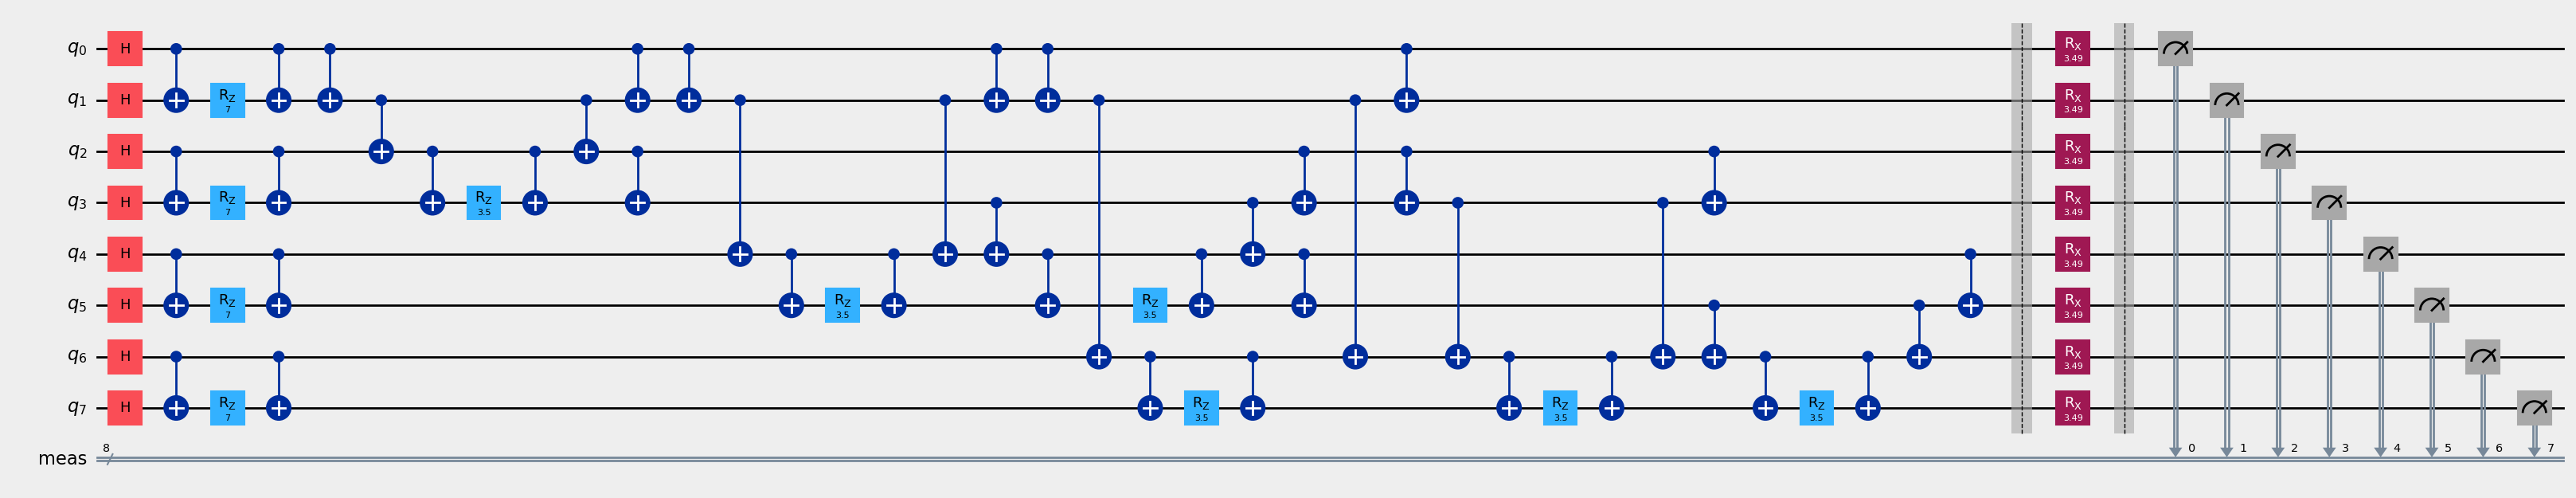

In [19]:
qc_res.draw(output='mpl', style={'backgroundcolor': '#EEEEEE'}, fold=-1) #This line visualizes the final QAOA circuit (qc_res) using Qiskit's circuit drawing capabilities. The `draw` method generates a graphical representation of the circuit, and the `output='mpl'` argument specifies that the output should be rendered using Matplotlib. The `style={'backgroundcolor': '#EEEEEE'}` argument sets the background color of the circuit diagram to a light gray color (#EEEEEE). This visualization helps to understand the structure and sequence of gates in the final QAOA circuit after optimization.

#### **Plot Measurements Histogram**
This section visualizes the measurement outcomes obtained from the final QAOA circuit. The histogram shows the frequency of each measured bitstring, allowing us to identify the most probable solutions.

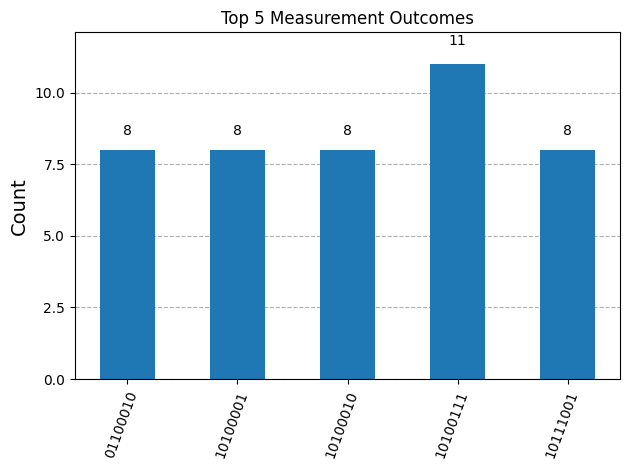

Top 5 Measurement Outcomes: {'10100111': 11, '01100010': 8, '10100001': 8, '10100010': 8, '10111001': 8}


In [20]:
top5 = dict(sorted(counts.items(), key=lambda item: item[1], reverse=True)[:5])   #This line sorts the measurement counts obtained from running the final QAOA circuit (qc_res) in descending order based on the frequency of each measured bitstring. The `sorted` function is used to sort the items in the `counts` dictionary, and the `key=lambda item: item[1]` argument specifies that the sorting should be based on the second element of each item (the count). The `reverse=True` argument ensures that the sorting is done in descending order. Finally, the `[:5]` slice selects the top 5 most frequent bitstrings, and the result is converted back into a dictionary using `dict()`. This allows us to focus on the most probable solutions obtained from the QAOA circuit.

hist = plot_histogram(top5, title="Top 5 Measurement Outcomes", bar_labels=True)   #This line generates a histogram plot of the top 5 measurement outcomes obtained from running the final QAOA circuit (qc_res). The `plot_histogram` function from Qiskit is used to create the histogram, and the `top5` dictionary containing the most frequent bitstrings and their corresponding counts is passed as input. The `title` argument sets the title of the histogram to "Top 5 Measurement Outcomes", and the `bar_labels=True` argument enables the display of count labels on each bar in the histogram. This visualization helps to identify the most probable solutions obtained from the QAOA circuit.
display(hist)   #This line displays the histogram plot generated in the previous line. The `display` function is used to render the histogram in the output of the notebook, allowing us to visualize the frequency of the top 5 measurement outcomes obtained from running the final QAOA circuit (qc_res).
print("Top 5 Measurement Outcomes:", top5)   #This line prints the top 5 measurement outcomes obtained from running the final QAOA circuit (qc_res). The `top5` dictionary contains the most frequent bitstrings and their corresponding counts, allowing us to see which solutions were most likely measured during the execution of the circuit.

#### **Convergence Analysis**
This graph shows how the expectation value of the Hamiltonian changes over the iterations of the classical optimization process. It provides insight into the convergence behavior of the QAOA algorithm and helps assess the effectiveness of the optimization in finding valid Williamson-type Hadamard matrices.

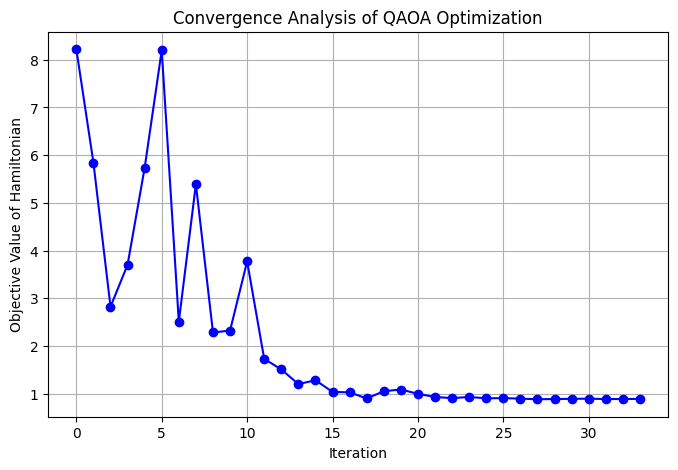

In [21]:
plt.figure(figsize=(8, 5))   #This line creates a new figure for plotting the convergence analysis. The `figsize` argument specifies the size of the figure in inches, with a width of 10 inches and a height of 6 inches. This provides a larger canvas for visualizing the convergence behavior of the QAOA algorithm.
plt.plot(vObj, marker='o', linestyle='-', color='b')   #This line plots the expectation values of the Hamiltonian (vObj) obtained during the optimization process. The `marker='o'` argument specifies that circular markers should be used for each data point, the `linestyle='-'` argument specifies that the data points should be connected by solid lines, and the `color='b'` argument specifies that the color of the plot should be blue.
plt.title("Convergence Analysis of QAOA Optimization")   #This line sets the title of the convergence analysis plot to "Convergence Analysis of QAOA Optimization". 
plt.xlabel("Iteration")   #This line sets the label for the x-axis of the convergence analysis plot to "Iteration".
plt.ylabel("Objective Value of Hamiltonian")   #This line sets the label for the y-axis of the convergence analysis plot to "Expectation Value of Hamiltonian". 
plt.grid()   #This line enables the grid lines on the convergence analysis plot, making it easier to read and interpret the data points.
plt.show()   #This line displays the convergence analysis plot generated in the previous lines. 

#### **Fine Best Candidate Solution**
This section identifies the best candidate solution from the measurement outcomes obtained from the final QAOA circuit. The best candidate is determined based on the lowest Hamiltonian energy, and it is further evaluated to check if it produces a valid Williamson-type Hadamard matrix.

In [22]:
counter = Counter(counts)   #This line creates a Counter object from the measurement counts obtained from running the final QAOA circuit (qc_res). The `Counter` class from the `collections` module is used to count the occurrences of each measured bitstring in the `counts` dictionary. This allows us to easily analyze the frequency of each measured outcome and identify the most probable solutions obtained from the QAOA circuit.
most_common = counter.most_common()   #This line retrieves the most common measurement outcome from the Counter object. The `most_common(1)` method returns a list containing a single tuple, where the first element is the most frequently measured bitstring and the second element is its corresponding count. This allows us to identify the best candidate solution based on the measurement outcomes obtained from running the final QAOA circuit (qc_res).

best_solution = None    #This line initializes the variable `best_solution` to `None`. It serves as a placeholder to store the best candidate solution found during the analysis of measurement outcomes. The best solution will be determined based on the lowest Hamiltonian energy and will be updated later in the code when a valid Williamson-type Hadamard matrix is identified.
best_value = 1e9   #This line initializes the variable `best_value` to a positive value (1e9). This value serves as a threshold for determining whether a candidate solution is considered valid based on its Hamiltonian energy. If the Hamiltonian energy of a candidate solution is less than or equal to this threshold, it will be considered a valid solution and may be selected as the best candidate solution.

for bitstring, freq in most_common:
    val = obj_williamson_12(bitstring)   #This line calculates the Hamiltonian energy of the current bitstring using the `obj_williamson_12` function. The function takes the bitstring as input and computes its corresponding energy based on the Williamson-type Hadamard matrix objective function. The calculated energy is stored in the variable `val`, which will be used to determine if this bitstring represents a valid solution with a low enough energy to be considered as the best candidate solution.

    if val < best_value:
        best_value = val   #This line updates the value of `best_value` to the current Hamiltonian energy `val` if it is less than or equal to the previous best value. This ensures that we keep track of the lowest Hamiltonian energy found so far during the analysis of measurement outcomes.
        best_solution = bitstring   #This line updates the variable `best_solution` to the current bitstring if its Hamiltonian energy `val` is less than or equal to the previous best value. This allows us to keep track of the bitstring that corresponds to the lowest Hamiltonian energy found during the analysis of measurement outcomes.

print("Best Candidate Solution:", best_solution)   #This line prints the best candidate solution found during the analysis of measurement outcomes. The variable `best_solution` contains the bitstring that corresponds to the lowest Hamiltonian energy identified in the previous loop. This output allows us to see which bitstring is considered the most promising solution based on the QAOA optimization results.
print("Minimum Hamiltonian Energy:", best_value)   #This line prints the minimum Hamiltonian energy associated with the best candidate solution found during the analysis of measurement outcomes. The variable `best_value` contains the lowest Hamiltonian energy identified in the previous loop, which corresponds to the best candidate solution. This output allows us to see the energy value that indicates how close the best candidate solution is to being a valid Williamson-type Hadamard matrix.

Best Candidate Solution: 10100111
Minimum Hamiltonian Energy: 0.0


#### **Construct Williamson-type Submatrices**
The solutioin bistring is converted into four submatrices $A, B, C,$ and $D$. Each submatrix is constructed based on the corresponding bits in the solution bitstring. The submatrices are then used to verify if they satisfy the Williamson construction condition.

In [23]:
def construct_ABCD(q):      #This line defines a function named `construct_ABCD` that takes a single argument `q`. The purpose of this function is to construct four submatrices (A, B, C, and D) based on the input bitstring `q`. Each submatrix will be constructed according to the corresponding bits in the solution bitstring, and the function will return these submatrices for further evaluation to check if they satisfy the Williamson construction condition.

    N = len(q)          # This line calculates the length of the input bitstring `q` and assigns it to the variable `N`. The length of the bitstring is used to determine the size of the submatrices A, B, C, and D that will be constructed based on the bits in `q`. The value of `N` will be used in subsequent calculations to define the dimensions of the submatrices.
    K05 = int(N/4)   # This line calculates the value of K05, which represents the size of each submatrix (A, B, C, and D). It is computed as one-fourth of the length of the input bitstring `q`, as each submatrix will be constructed from a quarter of the bits in `q`. The value of K05 will be used to define the dimensions of the submatrices and to extract the corresponding bits from the input bitstring.

    A = [q[0:K05], q[K05-1:0:-1]]   # This line constructs the submatrix A using the first K05 bits of the input bitstring `q`. The first part `q[0:K05]` extracts the first K05 bits in their original order, while the second part `q[K05-1:0:-1]` extracts the same bits in reverse order. This creates a symmetric structure for submatrix A, which is a requirement for the Williamson construction.
    B = [q[K05:2*K05], q[2*K05-1:K05:-1]]   # This line constructs the submatrix B using the next K05 bits of the input bitstring `q`. The first part `q[K05:2*K05]` extracts the next K05 bits in their original order, while the second part `q[2*K05-1:K05:-1]` extracts the same bits in reverse order. This creates a symmetric structure for submatrix B, which is a requirement for the Williamson construction.
    C = [q[2*K05:3*K05], q[3*K05-1:2*K05:-1]]   # This line constructs the submatrix C using the next K05 bits of the input bitstring `q`. The first part `q[2*K05:3*K05]` extracts the next K05 bits in their original order, while the second part `q[3*K05-1:2*K05:-1]` extracts the same bits in reverse order. This creates a symmetric structure for submatrix C, which is a requirement for the Williamson construction.
    D = [q[3*K05:4*K05], q[4*K05-1:3*K05:-1]]   # This line constructs the submatrix D using the last K05 bits of the input bitstring `q`. The first part `q[3*K05:4*K05]` extracts the last K05 bits in their original order, while the second part `q[4*K05-1:3*K05:-1]` extracts the same bits in reverse order. This creates a symmetric structure for submatrix D, which is a requirement for the Williamson construction.

    qA = [] 
    for item in A:
        qA.extend(item)     # This line iterates over each item in the submatrix A and extends the list qA with the elements of each item. The purpose of this operation is to flatten the submatrix A into a single list (qA) that contains all the bits from A in a sequential manner. This allows for easier manipulation and evaluation of the bits in submatrix A for further processing or analysis.
    qB = [] 
    for item in B:
        qB.extend(item)     # This line iterates over each item in the submatrix B and extends the list qB with the elements of each item. The purpose of this operation is to flatten the submatrix B into a single list (qB) that contains all the bits from B in a sequential manner. This allows for easier manipulation and evaluation of the bits in submatrix B for further processing or analysis.
    qC = [] 
    for item in C:
        qC.extend(item)     # This line iterates over each item in the submatrix C and extends the list qC with the elements of each item. The purpose of this operation is to flatten the submatrix C into a single list (qC) that contains all the bits from C in a sequential manner. This allows for easier manipulation and evaluation of the bits in submatrix C for further processing or analysis.
    qD = [] 
    for item in D:
        qD.extend(item)     # This line iterates over each item in the submatrix D and extends the list qD with the elements of each item. The purpose of this operation is to flatten the submatrix D into a single list (qD) that contains all the bits from D in a sequential manner. This allows for easier manipulation and evaluation of the bits in submatrix D for further processing or analysis.

    NN = 2*K05 - 1   # This line calculates the value of NN, which represents the size of the submatrices A, B, C, and D after flattening. It is computed as twice the value of K05 minus 1. The value of NN will be used to define the dimensions of the submatrices and to facilitate further processing or analysis of the bits in the flattened submatrices.

    A = np.empty((NN, NN), dtype=object)   # This line creates an empty NumPy array A with dimensions (NN, NN) and data type int. The array will be used to store the bits of submatrix A in a 2D format, allowing for easier manipulation and evaluation of the bits in submatrix A for further processing or analysis.
    B = np.empty((NN, NN), dtype=object)   # This line creates an empty NumPy array B with dimensions (NN, NN) and data type int. The array will be used to store the bits of submatrix B in a 2D format, allowing for easier manipulation and evaluation of the bits in submatrix B for further processing or analysis.
    C = np.empty((NN, NN), dtype=object)   # This line creates an empty NumPy array C with dimensions (NN, NN) and data type int. The array will be used to store the bits of submatrix C in a 2D format, allowing for easier manipulation and evaluation of the bits in submatrix C for further processing or analysis.
    D = np.empty((NN, NN), dtype=object)   # This line creates an empty NumPy array D with dimensions (NN, NN) and data type int. The array will be used to store the bits of submatrix D in a 2D format, allowing for easier manipulation and evaluation of the bits in submatrix D for further processing or analysis.
    
    A[:,0] = qA     # This line assigns the flattened list of bits from submatrix A (qA) to the first column of the 2D NumPy array A. The `:` operator indicates that all rows of the first column (index 0) will be filled with the values from qA. This operation effectively populates the first column of the submatrix A with the corresponding bits, allowing for further manipulation and evaluation of the bits in submatrix A in a 2D format.
    B[:,0] = qB     # This line assigns the flattened list of bits from submatrix B (qB) to the first column of the 2D NumPy array B. The `:` operator indicates that all rows of the first column (index 0) will be filled with the values from qB. This operation effectively populates the first column of the submatrix B with the corresponding bits, allowing for further manipulation and evaluation of the bits in submatrix B in a 2D format.
    C[:,0] = qC     # This line assigns the flattened list of bits from submatrix C (qC) to the first column of the 2D NumPy array C. The `:` operator indicates that all rows of the first column (index 0) will be filled with the values from qC. This operation effectively populates the first column of the submatrix C with the corresponding bits, allowing for further manipulation and evaluation of the bits in submatrix C in a 2D format.
    D[:,0] = qD     # This line assigns the flattened list of bits from submatrix D (qD) to the first column of the 2D NumPy array D. The `:` operator indicates that all rows of the first column (index 0) will be filled with the values from qD. This operation effectively populates the first column of the submatrix D with the corresponding bits, allowing for further manipulation and evaluation of the bits in submatrix D in a 2D format.  

    for i in range(1, NN):   # This line starts a loop that iterates over the range from 1 to NN-1 (inclusive). The purpose of this loop is to fill the remaining columns of the 2D NumPy arrays A, B, C, and D with the corresponding bits from the flattened lists qA, qB, qC, and qD. The loop index `i` represents the current column being filled in each submatrix.
        A[:,i] = np.roll(A, i)   # This line rolls the elements of the 2D NumPy array A along the rows (axis=0) by `i` positions. The `np.roll` function shifts the elements of the array, effectively creating a cyclic permutation of the bits in submatrix A. This operation fills the `i`-th column of submatrix A with the corresponding bits from the previous columns, ensuring that the symmetric structure of submatrix A is maintained.
        B[:,i] = np.roll(B, i)   # This line rolls the elements of the 2D NumPy array B along the rows (axis=0) by `i` positions. The `np.roll` function shifts the elements of the array, effectively creating a cyclic permutation of the bits in submatrix B. This operation fills the `i`-th column of submatrix B with the corresponding bits from the previous columns, ensuring that the symmetric structure of submatrix B is maintained.
        C[:,i] = np.roll(C, i)   # This line rolls the elements of the 2D NumPy array C along the rows (axis=0) by `i` positions. The `np.roll` function shifts the elements of the array, effectively creating a cyclic permutation of the bits in submatrix C. This operation fills the `i`-th column of submatrix C with the corresponding bits from the previous columns, ensuring that the symmetric structure of submatrix C is maintained.
        D[:,i] = np.roll(D, i)   # This line rolls the elements of the 2D NumPy array D along the rows (axis=0) by `i` positions. The `np.roll` function shifts the elements of the array, effectively creating a cyclic permutation of the bits in submatrix D. This operation fills the `i`-th column of submatrix D with the corresponding bits from the previous columns, ensuring that the symmetric structure of submatrix D is maintained.   

    return A, B, C, D   # This line returns the constructed submatrices A, B, C, and D as output from the `construct_ABCD` function. The submatrices are returned in a tuple format, allowing them to be easily unpacked and used for further evaluation or analysis to check if they satisfy the Williamson construction condition.

#### **Construct Williamson-type Hadamard Matrices**
The Williamson-type Hadamard matrix is constructed using the four submatrices $A, B, C,$ and $D$. The final Hadamard matrix is formed by arranging these submatrices in a specific pattern, ensuring that the resulting matrix satisfies the properties of a Hadamard matrix:
$$\begin{bmatrix} A & B & C & D \\
- B & A & -D & -C \\
- C & D & A & -B \\
- D & -C & B & A \end{bmatrix}$$

In [24]:
def construct_symm_williamson(A, B, C, D):   # This line defines a function named `construct_symm_williamson` that takes four arguments: A, B, C, and D. The purpose of this function is to construct a symmetric Williamson-type Hadamard matrix using the provided submatrices A, B, C, and D. The function will combine these submatrices in a specific manner to create the final Williamson matrix.

    M, N = A.shape  # This line retrieves the number of rows (or columns) in the submatrix A and assigns it to the variable N. Since A is a square matrix, N represents the size of the submatrices A, B, C, and D. This value will be used to define the dimensions of the final Williamson matrix.

    W = np.empty((4*M, 4*N), dtype=object)   # This line creates an empty NumPy array W with dimensions (4*N, 4*N) and data type int. The array will be used to store the final Williamson-type Hadamard matrix constructed from the submatrices A, B, C, and D. The size of W is determined by multiplying N by 4, as the Williamson matrix is constructed by combining four submatrices.

    W[0:M,0:M] = A   # This line assigns the submatrix A to the top-left quadrant of the Williamson matrix W. The slice `W[0:N, 0:N]` specifies that the first N rows and first N columns of W will be filled with the values from submatrix A.

    W[0:M, M:2*M] = B   # This line assigns the submatrix B to the top-right quadrant of the Williamson matrix W. The slice `W[0:N, N:2*N]` specifies that the first N rows and columns from N to 2*N of W will be filled with the values from submatrix B.

    W[0:M, 2*M:3*M] = C   # This line assigns the submatrix C to the bottom-left quadrant of the Williamson matrix W. The slice `W[0:N, 2*N:3*N]` specifies that the first N rows and columns from 2*N to 3*N of W will be filled with the values from submatrix C.

    W[0:M, 3*M:4*M] = D   # This line assigns the submatrix D to the bottom-right quadrant of the Williamson matrix W. The slice `W[0:N, 3*N:4*N]` specifies that the first N rows and columns from 3*N to 4*N of W will be filled with the values from submatrix D.    


    W[M:2*M,0:M] = -B   # This line assigns the negated submatrix B to the bottom-left quadrant of the Williamson matrix W. The slice `W[N:2*N, 0:N]` specifies that the rows from N to 2*N and the first N columns of W will be filled with the negated values from submatrix B. The negation is performed to ensure that the resulting Williamson matrix satisfies the required properties for a valid Williamson-type Hadamard matrix.
    W[M:2*M, M:2*M] = A   # This line assigns the submatrix A to the bottom-right quadrant of the Williamson matrix W. The slice `W[N:2*N, N:2*N]` specifies that the rows from N to 2*N and columns from N to 2*N of W will be filled with the values from submatrix A.
    W[M:2*M, 2*M:3*M] = -D   # This line assigns the negated submatrix D to the bottom-left quadrant of the Williamson matrix W. The slice `W[N:2*N, 2*N:3*N]` specifies that the rows from N to 2*N and columns from 2*N to 3*N of W will be filled with the negated values from submatrix D. The negation is performed to ensure that the resulting Williamson matrix satisfies the required properties for a valid Williamson-type Hadamard matrix.
    W[M:2*M, 3*M:4*M] = C   # This line assigns the submatrix C to the bottom-right quadrant of the Williamson matrix W. The slice `W[N:2*N, 3*N:4*N]` specifies that the rows from N to 2*N and columns from 3*N to 4*N of W will be filled with the values from   submatrix C.                
    
    
    W[2*M:3*M,0:M] = -C   # This line assigns the negated submatrix C to the bottom-left quadrant of the Williamson matrix W. The slice `W[2*N:3*N, 0:N]` specifies that the rows from 2*N to 3*N and the first N columns of W will be filled with the negated values from submatrix C. The negation is performed to ensure that the resulting Williamson matrix satisfies the required properties for a valid Williamson-type Hadamard matrix.
    W[2*M:3*M, M:2*M] = D   # This line assigns the submatrix D to the bottom-right quadrant of the Williamson matrix W. The slice `W[2*N:3*N, N:2*N]` specifies that the rows from 2*N to 3*N and columns from N to 2*N of W will be filled with the values from submatrix D.
    W[2*M:3*M, 2*M:3*M] = A   # This line assigns the submatrix A to the bottom-right quadrant of the Williamson matrix W. The slice `W[2*N:3*N, 2*N:3*N]` specifies that the rows from 2*N to 3*N and columns from 2*N to 3*N of W will be filled with the values from submatrix A.
    W[2*M:3*M, 3*M:4*M] = -B   # This line assigns the negated submatrix B to the bottom-right quadrant of the Williamson matrix W. The slice `W[2*N:3*N, 3*N:4*N]` specifies that the rows from 2*N to 3*N and columns from 3*N to 4*N of W will be filled with the negated values from submatrix B. The negation is performed to ensure that the resulting Williamson matrix satisfies the required properties for a valid Williamson-type Hadamard matrix.   

    W[3*M:4*M,0:M] = -D   # This line assigns the negated submatrix D to the bottom-left quadrant of the Williamson matrix W. The slice `W[3*N:4*N, 0:N]` specifies that the rows from 3*N to 4*N and the first N columns of W will be filled with the negated values from submatrix D. The negation is performed to ensure that the resulting Williamson matrix satisfies the required properties for a valid Williamson-type Hadamard matrix.
    W[3*M:4*M, M:2*M] = -C   # This line assigns the negated submatrix C to the bottom-right quadrant of the Williamson matrix W. The slice `W[3*N:4*N, N:2*N]` specifies that the rows from 3*N to 4*N and columns from N to 2*N of W will be filled with the negated values from submatrix C. The negation is performed to ensure that the resulting Williamson matrix satisfies the required properties for a valid Williamson-type Hadamard matrix.
    W[3*M:4*M, 2*M:3*M] = B   # This line assigns the submatrix B to the bottom-right quadrant of the Williamson matrix W. The slice `W[3*N:4*N, 2*N:3*N]` specifies that the rows from 3*N to 4*N and columns from 2*N to 3*N of W will be filled with the values from submatrix B.
    W[3*M:4*M, 3*M:4*M] = A   # This line assigns the submatrix A to the bottom-right quadrant of the Williamson matrix W. The slice `W[3*N:4*N, 3*N:4*N]` specifies that the rows from 3*N to 4*N and columns from 3*N to 4*N of W will be filled with the values from submatrix A.    

    return W   # This line returns the constructed Williamson-type Hadamard matrix W as output from the `construct_symm_williamson` function. The matrix W is returned as a 2D NumPy array, allowing it to be easily manipulated and evaluated for further analysis or verification of its properties as a valid Williamson-type Hadamard matrix.   


#### **Build Final Hadamard Matrix**
Now that we have constructed the submatrices $A, B, C,$ and $D$, we can build the final Williamson-type Hadamard matrix by arranging these submatrices in the specified pattern. The resulting matrix will be a valid Hadamard matrix of order 12 if the submatrices satisfy the Williamson construction condition.

In [25]:
spin = [binary_to_spin(int(x)) for x in best_solution]

def construct_ABCD(q):
    q = list(q)
    K = len(q) // 4
    NN = 2 * K - 1

    sequences = [
        q[0:K] + q[K - 1:0:-1],
        q[K:2 * K] + q[2 * K - 1:K:-1],
        q[2 * K:3 * K] + q[3 * K - 1:2 * K:-1],
        q[3 * K:4 * K] + q[4 * K - 1:3 * K:-1],
    ]

    matrices = []
    for sequence in sequences:
        first_column = np.asarray(sequence, dtype=int)
        matrix = np.column_stack([
            np.roll(first_column, i) for i in range(NN)
        ])
        matrices.append(matrix)

    return tuple(matrices)

A, B, C, D = construct_ABCD(spin)

W = np.block([
    [ A,  B,  C,  D],
    [-B,  A, -D, -C],
    [-C,  D,  A, -B],
    [-D, -C,  B,  A],
])

DG = W @ W.transpose()
print(DG)

DG = np.matmul(W, W.transpose())        # Multiply two matrices together

[[12  0  0 -2 -2 -2  0  0  0  0  0  0]
 [ 0 12  0 -2 -2 -2  0  0  0  0  0  0]
 [ 0  0 12 -2 -2 -2  0  0  0  0  0  0]
 [-2 -2 -2 12  0  0 -6  2  2  6 -2 -2]
 [-2 -2 -2  0 12  0  2 -6  2 -2  6 -2]
 [-2 -2 -2  0  0 12  2  2 -6 -2 -2  6]
 [ 0  0  0 -6  2  2 12  0  0  0  0  0]
 [ 0  0  0  2 -6  2  0 12  0  0  0  0]
 [ 0  0  0  2  2 -6  0  0 12  0  0  0]
 [ 0  0  0  6 -2 -2  0  0  0 12  0  0]
 [ 0  0  0 -2  6 -2  0  0  0  0 12  0]
 [ 0  0  0 -2 -2  6  0  0  0  0  0 12]]


#### **Visualize the Orthogonality matrix**
If the construction is correct: 
$$WW^T = nI$$

Therefore, we can visualize the orthogonality matrix $WW^T$ to verify that it is indeed equal to $nI$. This serves as a final check to confirm that the constructed Williamson-type Hadamard matrix satisfies the orthogonality condition.

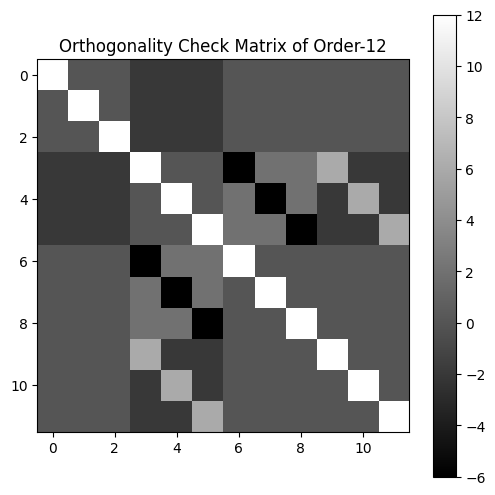

In [26]:
plt.figure(figsize=(6,6))
plt.imshow(DG.astype(float), cmap='gray')
plt.title('Orthogonality Check Matrix of Order-12')
plt.colorbar()
plt.show()
